name-ujjawal chauhan  labsheet-06

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load California Housing Dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Dataset Shape: (20640, 9)

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target: MedHouseVal
Target represents median house value in units of $100,000.


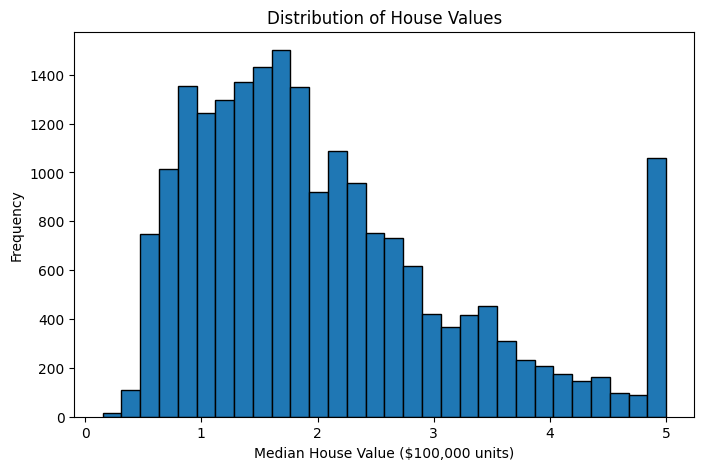

In [2]:
# Separate features and target
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

# Handle missing values
X = X.fillna(X.mean())
y = y.fillna(y.mean())

# Display dataset information
print("Features:")
print(X.columns.tolist())

print("\nTarget: MedHouseVal")
print("Target represents median house value in units of $100,000.")

# Visualize target distribution
plt.figure(figsize=(8, 5))
plt.hist(y, bins=30, edgecolor="black")
plt.title("Distribution of House Values")
plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Frequency")
plt.show()

In [3]:
# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Predict house values
y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Model trained successfully!
Training samples: 16512
Testing samples: 4128

First 10 Actual Values:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

First 10 Predicted Values:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


Model Performance
-------------------------
MAE : 0.5332
MSE : 0.5559
RMSE: 0.7456
R2 Score: 0.5758


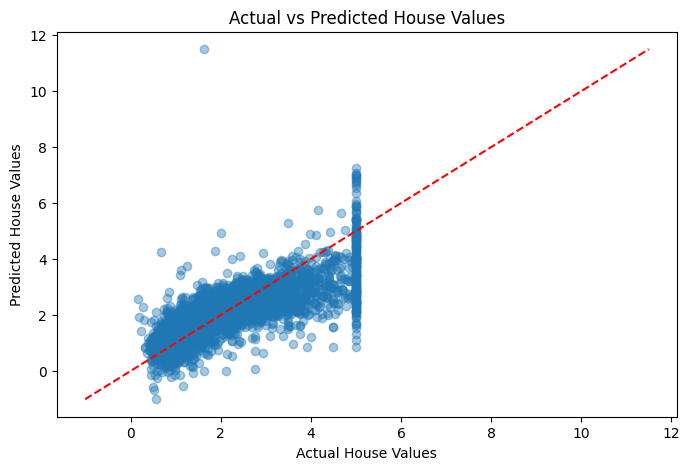

In [5]:
# Calculate regression metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("-------------------------")
print("MAE :", round(mae, 4))
print("MSE :", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

# Compare actual and predicted values
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")

# Ideal prediction line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--")

plt.show()

Regression Coefficients:
      Feature  Coefficient
3   AveBedrms     0.783145
0      MedInc     0.448675
1    HouseAge     0.009724
4  Population    -0.000002
5    AveOccup    -0.003526
2    AveRooms    -0.123323
6    Latitude    -0.419792
7   Longitude    -0.433708


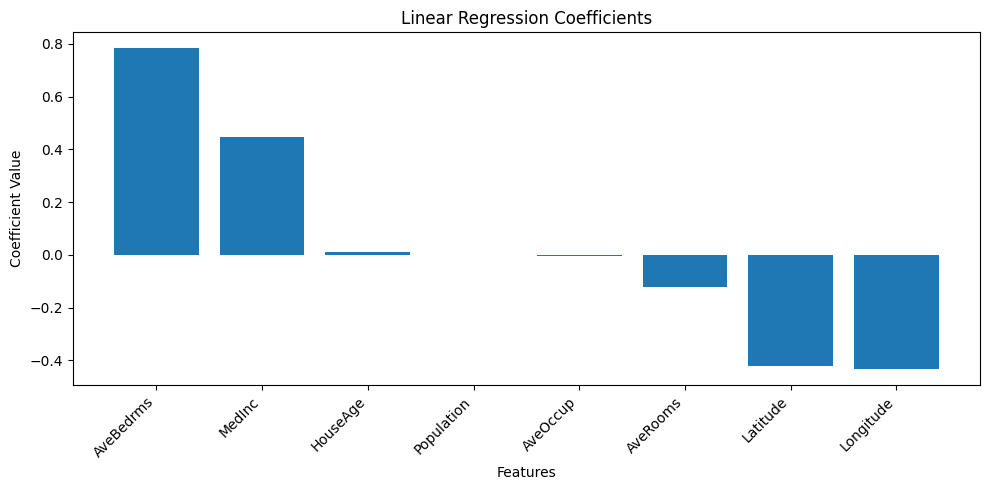

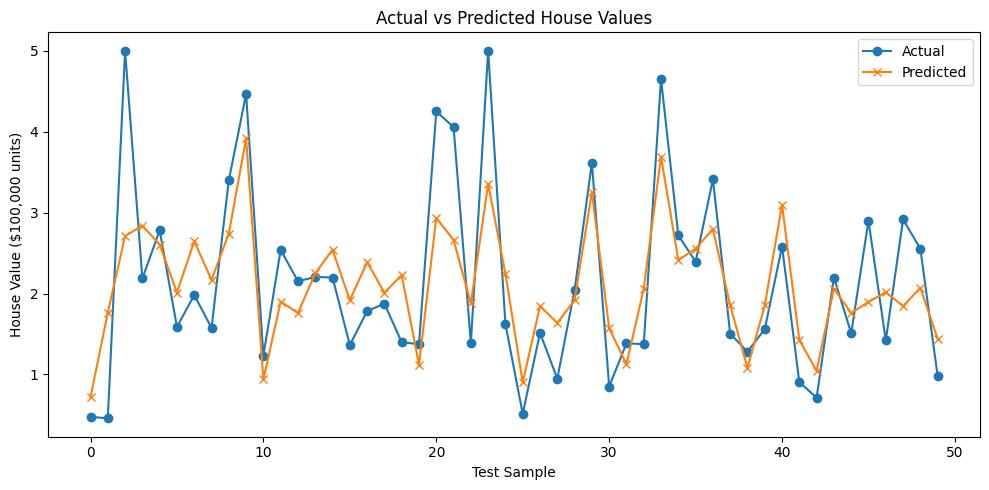

In [4]:
# Display regression coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

print("Regression Coefficients:")
print(coefficients)

# Visualize coefficient impact
plt.figure(figsize=(10, 5))
plt.bar(
    coefficients["Feature"],
    coefficients["Coefficient"]
)
plt.title("Linear Regression Coefficients")
plt.xlabel("Features")
plt.ylabel("Coefficient Value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Plot actual and predicted values for first 50 test samples
plt.figure(figsize=(10, 5))
plt.plot(y_test.values[:50], label="Actual", marker="o")
plt.plot(y_pred[:50], label="Predicted", marker="x")
plt.title("Actual vs Predicted House Values")
plt.xlabel("Test Sample")
plt.ylabel("House Value ($100,000 units)")
plt.legend()
plt.tight_layout()
plt.show()